# CV_PR3 — Computer Vision Project
**Red & White Skill Education | Deep Learning | PR 3**

This notebook follows the PDF's five tasks: (1) morphology, (2) bitwise operations and histograms, (3) YuNet face detection, (4) YOLOv8 object detection, and (5) an integrated pipeline.

Static-image sections are designed for Run All. Webcam work is provided as optional functions so the notebook does not hang waiting for camera input. Downloaded assets are saved under `data/images/` and `data/models/`; figures are saved under `plots/`.

## Setup — Dependencies

The PDF specifies `opencv-python==5.0.0.*`, `opencv-contrib-python==5.0.0.*`, `ultralytics`, `matplotlib`, and `numpy`. Uncomment the install command if required. If OpenCV 5 is unavailable for your Python/platform, install a compatible version supporting `FaceDetectorYN` and record the actual version.

OpenCV version: 5.0.0
NumPy version: 2.1.3
Colour shape/dtype: (512, 512, 3) uint8
Grayscale shape/dtype: (356, 413) uint8


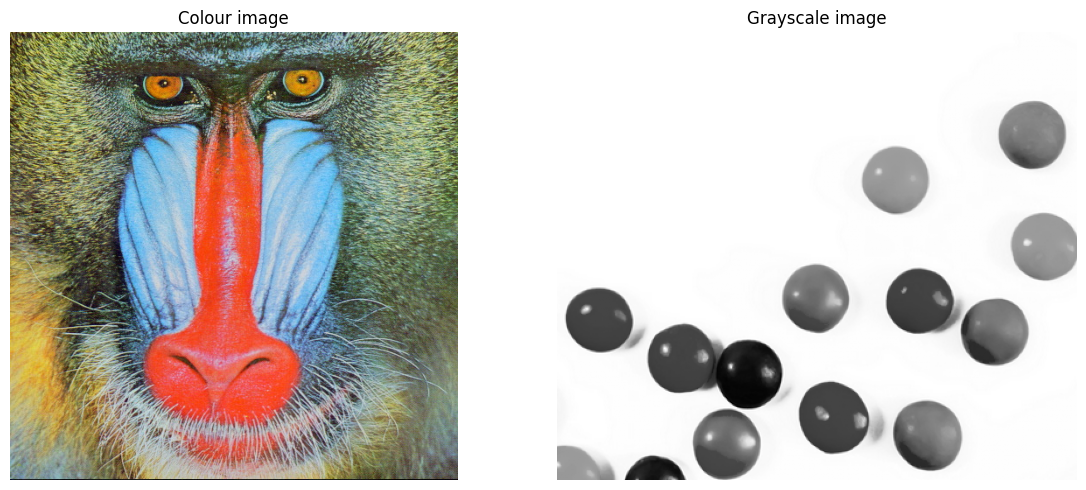

In [ ]:
# %pip install "opencv-python==5.0.0.*" "opencv-contrib-python==5.0.0.*" ultralytics matplotlib numpy

import os, time, urllib.request
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

IMAGE_DIR = Path("data/images")
MODEL_DIR = Path("data/models")
PLOT_DIR = Path("plots")
for folder in (IMAGE_DIR, MODEL_DIR, PLOT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

def show(img, title="Image", ax=None, cmap=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    if img is None:
        ax.set_title(title + " — unavailable")
        ax.axis("off")
    elif img.ndim == 3:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    else:
        ax.imshow(img, cmap=cmap or "gray")
        ax.set_title(title)
        ax.axis("off")
    return ax

def download_file(url, path):
    if path.exists() and path.stat().st_size > 1000:
        return True
    try:
        request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=25) as response:
            content = response.read()
        if len(content) < 1000:
            raise ValueError("Downloaded file is too small.")
        path.write_bytes(content)
        print("Downloaded:", path)
        return True
    except Exception as exc:
        print(f"Download failed for {path.name}: {exc}")
        return False

# URLs are checked at runtime; if unavailable, simple synthetic images are generated.
urls = {
    "baboon.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/baboon.jpg",
    "smarties.png": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/smarties.png",
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg",
}
for name, url in urls.items():
    download_file(url, IMAGE_DIR / name)

def make_fallback(path):
    img = np.full((480, 640, 3), 245, dtype=np.uint8)
    cv2.rectangle(img, (70, 80), (250, 300), (30, 80, 220), -1)
    cv2.circle(img, (390, 200), 90, (30, 180, 70), -1)
    cv2.line(img, (40, 400), (590, 350), (200, 40, 40), 12)
    cv2.putText(img, "CV PR3 sample", (120, 450), cv2.FONT_HERSHEY_SIMPLEX, 1, (20, 20, 20), 2)
    cv2.imwrite(str(path), img)

for name in urls:
    p = IMAGE_DIR / name
    if cv2.imread(str(p)) is None:
        make_fallback(p)
        print("Created fallback image:", p)

img_colour = cv2.imread(str(IMAGE_DIR / "baboon.jpg"), cv2.IMREAD_COLOR)
img_gray = cv2.imread(str(IMAGE_DIR / "smarties.png"), cv2.IMREAD_GRAYSCALE)
print("Colour shape/dtype:", img_colour.shape, img_colour.dtype)
print("Grayscale shape/dtype:", img_gray.shape, img_gray.dtype)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
show(img_colour, "Colour image", ax[0])
show(img_gray, "Grayscale image", ax[1])
plt.tight_layout()
plt.show()

# Task 1: Environment Setup, Image I/O & Morphological Operations

## 1.2 Binarize a Test Image
**Objective:** Convert the colour image to grayscale and threshold it at 127; show the original grayscale and binary result.

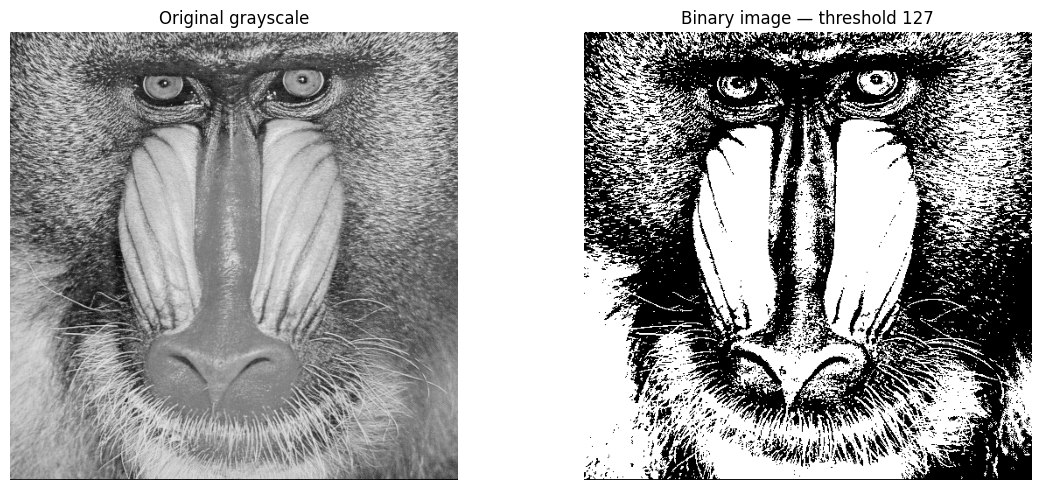

In [ ]:
gray_for_threshold = cv2.cvtColor(img_colour, cv2.COLOR_BGR2GRAY)
_, binary_img = cv2.threshold(gray_for_threshold, 127, 255, cv2.THRESH_BINARY)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
show(gray_for_threshold, "Original grayscale", ax[0])
show(binary_img, "Binary image — threshold 127", ax[1])
plt.tight_layout()
plt.show()

## 1.3 Apply the Four Morphological Operations
**Objective:** Apply erosion, dilation, opening and closing with a 5×5 rectangular kernel; compare in a 1×5 grid.

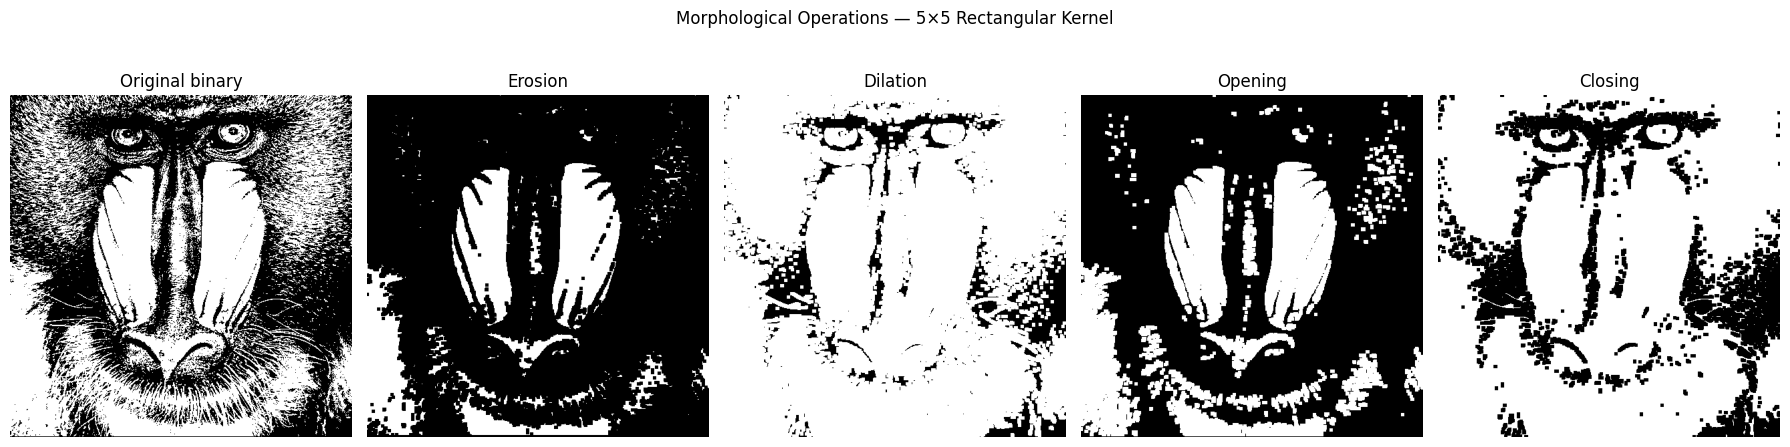

In [ ]:
kernel = np.ones((5, 5), np.uint8)
eroded = cv2.erode(binary_img, kernel, iterations=1)
dilated = cv2.dilate(binary_img, kernel, iterations=1)
opened = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel)

fig, ax = plt.subplots(1, 5, figsize=(18, 5))
for a, im, title in zip(ax, [binary_img, eroded, dilated, opened, closed],
                        ["Original binary", "Erosion", "Dilation", "Opening", "Closing"]):
    show(im, title, a)
fig.suptitle("Morphological Operations — 5×5 Rectangular Kernel")
plt.tight_layout()
plt.savefig(PLOT_DIR / "morphology_grid.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.4 Kernel Shape & Size Comparison
**Objective:** Compare opening and closing using RECT, ELLIPSE and CROSS kernels of 3×3, 5×5 and 9×9 on a noisy binary image.

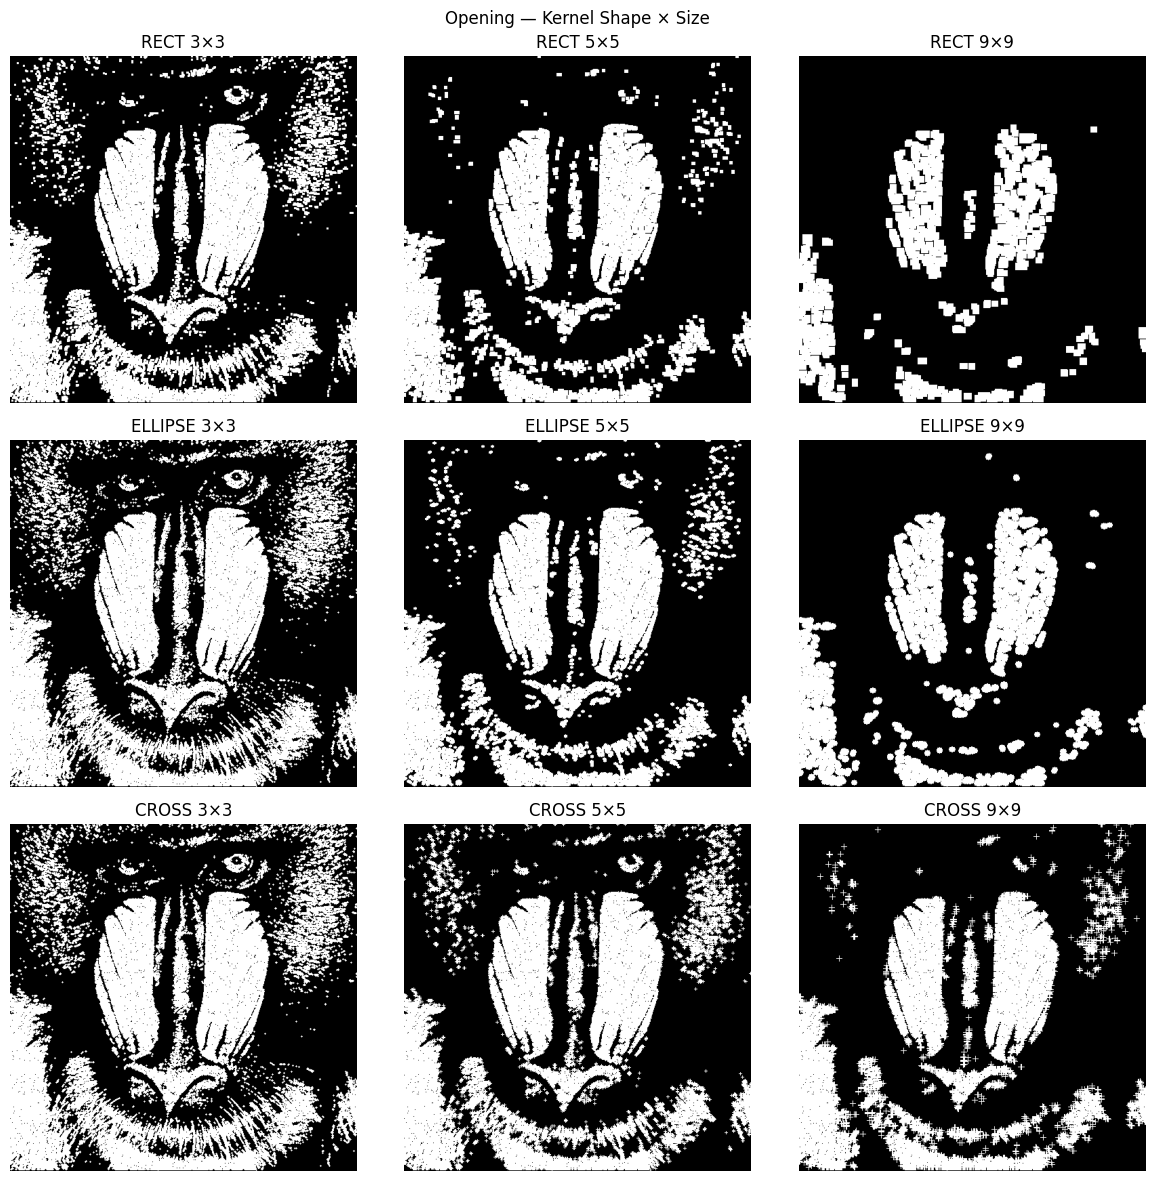

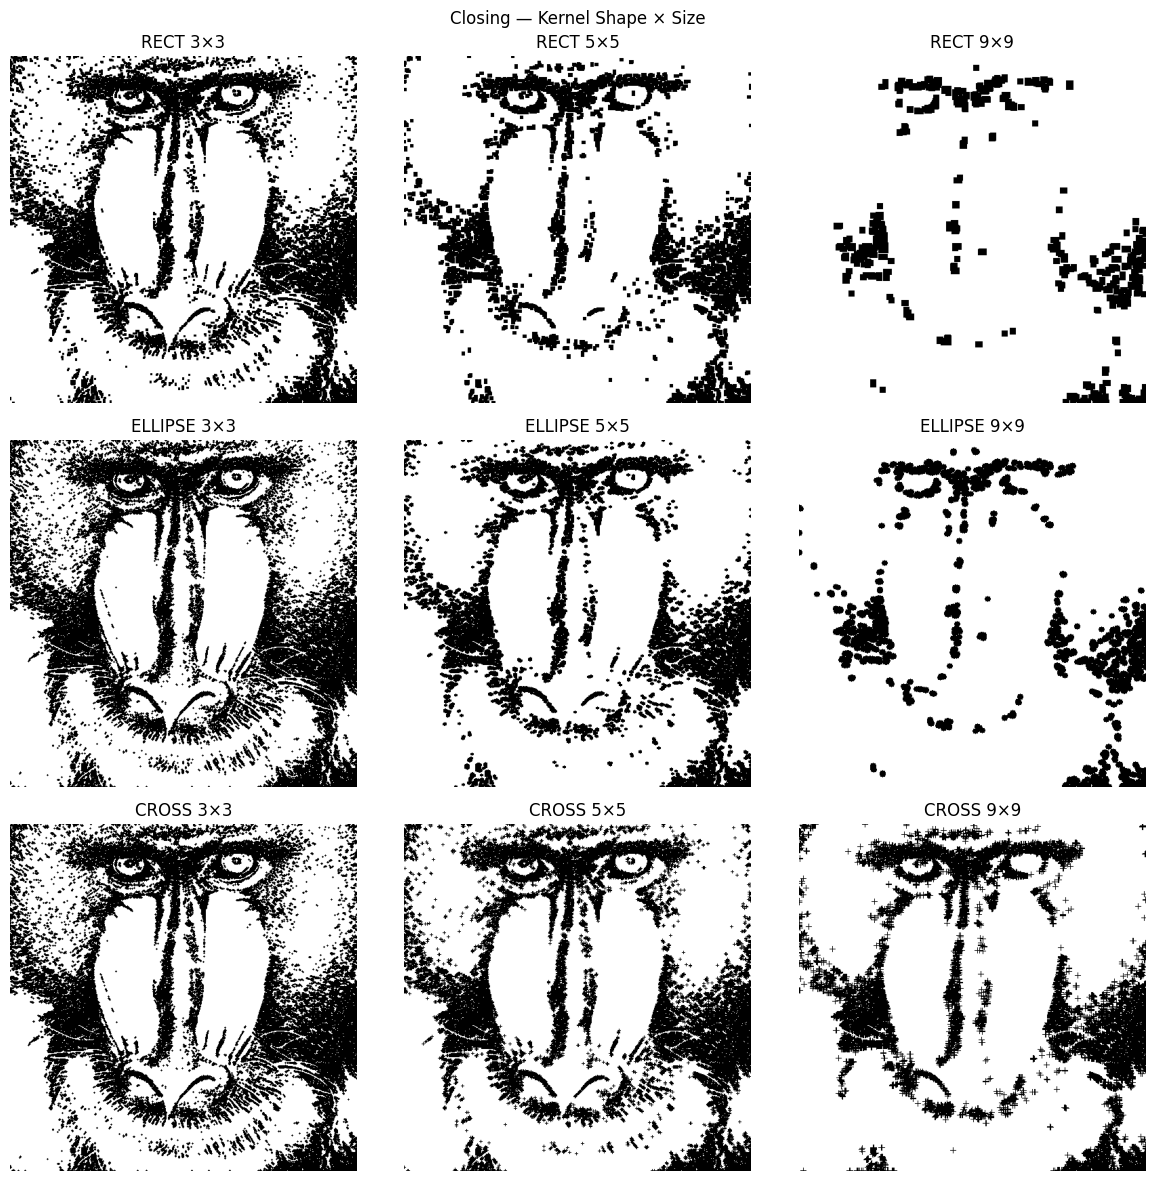

In [ ]:
rng = np.random.default_rng(42)
noisy_binary = binary_img.copy()
noise_mask = rng.random(noisy_binary.shape) < 0.025
salt_mask = rng.random(noisy_binary.shape) < 0.5
noisy_binary[noise_mask & salt_mask] = 255
noisy_binary[noise_mask & ~salt_mask] = 0

shapes = {"RECT": cv2.MORPH_RECT, "ELLIPSE": cv2.MORPH_ELLIPSE, "CROSS": cv2.MORPH_CROSS}
for op_name, op_code in [("Opening", cv2.MORPH_OPEN), ("Closing", cv2.MORPH_CLOSE)]:
    fig, ax = plt.subplots(3, 3, figsize=(12, 12))
    for r, (shape_name, shape_code) in enumerate(shapes.items()):
        for c, size in enumerate([3, 5, 9]):
            element = cv2.getStructuringElement(shape_code, (size, size))
            result = cv2.morphologyEx(noisy_binary, op_code, element)
            show(result, f"{shape_name} {size}×{size}", ax[r, c])
    fig.suptitle(op_name + " — Kernel Shape × Size")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{op_name.lower()}_kernel_grid.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1.5 WHY Morphology Works

Erosion acts like a local minimum filter: it shrinks white regions and removes small bright noise. Dilation acts like a local maximum filter: it grows white regions and fills small dark gaps.

- **Opening = erosion → dilation:** removes small foreground noise while generally preserving the main shape. Use it to clean isolated white specks from a thresholded inspection mask.
- **Closing = dilation → erosion:** fills small holes and gaps. Use it to repair breaks in a mask before contour measurement.

Kernel size matters: a large kernel can erase thin details or merge separate objects. Choose from the plotted comparison based on the image.

# Task 2: Bitwise Operations & Image Histograms

## 2.1 Bitwise AND / OR / XOR / NOT
**Objective:** Create circle and rectangle masks and plot both masks plus AND, OR, XOR and NOT results in a 2×3 grid.

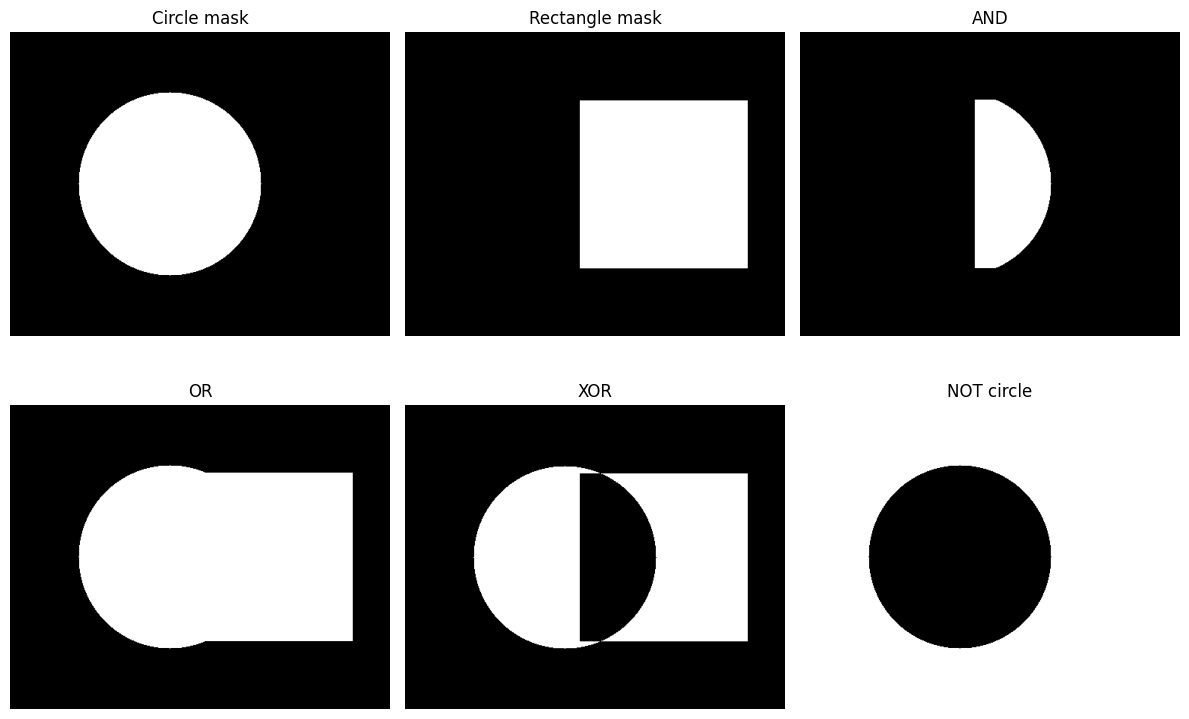

In [ ]:
mask_a = np.zeros((400, 500), dtype=np.uint8)
mask_b = np.zeros((400, 500), dtype=np.uint8)
cv2.circle(mask_a, (210, 200), 120, 255, -1)
cv2.rectangle(mask_b, (230, 90), (450, 310), 255, -1)
bitwise_items = [
    (mask_a, "Circle mask"), (mask_b, "Rectangle mask"),
    (cv2.bitwise_and(mask_a, mask_b), "AND"),
    (cv2.bitwise_or(mask_a, mask_b), "OR"),
    (cv2.bitwise_xor(mask_a, mask_b), "XOR"),
    (cv2.bitwise_not(mask_a), "NOT circle"),
]
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for a, (im, title) in zip(ax.ravel(), bitwise_items):
    show(im, title, a)
plt.tight_layout()
plt.savefig(PLOT_DIR / "bitwise_grid.png", dpi=150, bbox_inches="tight")
plt.show()

## 2.2 Applied Use Case: Masked Overlay
**Objective:** Extract a circular region from a photo and demonstrate a simple bitwise-OR logo overlay.

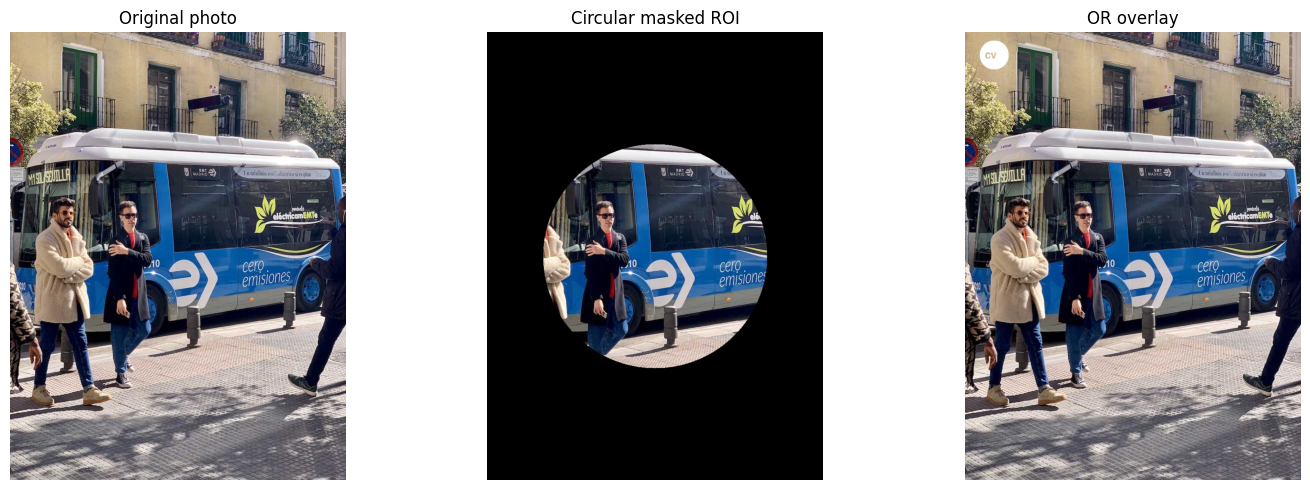

In [ ]:
photo = cv2.imread(str(IMAGE_DIR / "bus.jpg"))
if photo is None:
    photo = img_colour.copy()
h, w = photo.shape[:2]
roi_mask = np.zeros((h, w), dtype=np.uint8)
cv2.circle(roi_mask, (w//2, h//2), max(20, min(h, w)//3), 255, -1)
masked_photo = cv2.bitwise_and(photo, photo, mask=roi_mask)

logo = np.zeros_like(photo)
cv2.circle(logo, (70, 55), 35, (255, 255, 255), -1)
cv2.putText(logo, "CV", (48, 64), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
overlay = cv2.bitwise_or(photo, logo)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
show(photo, "Original photo", ax[0])
show(masked_photo, "Circular masked ROI", ax[1])
show(overlay, "OR overlay", ax[2])
plt.tight_layout()
plt.savefig(PLOT_DIR / "masked_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

## 2.3 Grayscale & Per-Channel Colour Histograms
**Objective:** Plot the grayscale histogram and overlay B/G/R channel histograms on one axes.

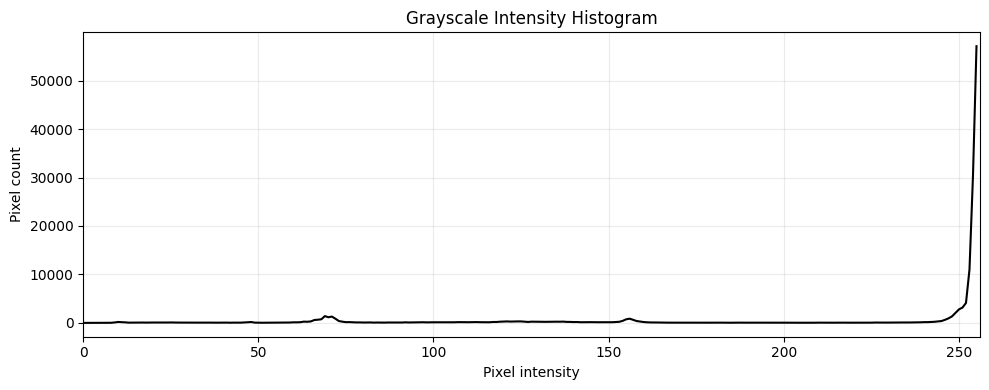

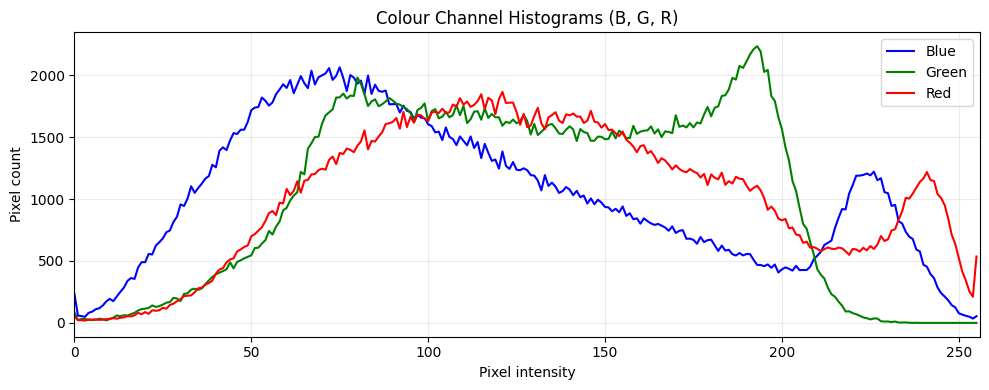

In [ ]:
gray_hist = cv2.calcHist([img_gray], [0], None, [256], [0, 256])
plt.figure(figsize=(10, 4))
plt.plot(gray_hist, color="black")
plt.title("Grayscale Intensity Histogram")
plt.xlabel("Pixel intensity"); plt.ylabel("Pixel count"); plt.xlim(0, 256); plt.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(PLOT_DIR / "grayscale_histogram.png", dpi=150); plt.show()

plt.figure(figsize=(10, 4))
for channel, colour, label in [(0, "blue", "Blue"), (1, "green", "Green"), (2, "red", "Red")]:
    hist = cv2.calcHist([img_colour], [channel], None, [256], [0, 256])
    plt.plot(hist, color=colour, label=label)
plt.title("Colour Channel Histograms (B, G, R)")
plt.xlabel("Pixel intensity"); plt.ylabel("Pixel count"); plt.xlim(0, 256); plt.legend(); plt.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(PLOT_DIR / "colour_histograms.png", dpi=150); plt.show()

## 2.4 Brightness & Contrast Adjustment
**Objective:** Compare original, brighter/higher-contrast (`alpha=1.5, beta=30`) and darker/lower-contrast (`alpha=0.7, beta=-30`) versions with grayscale histograms.

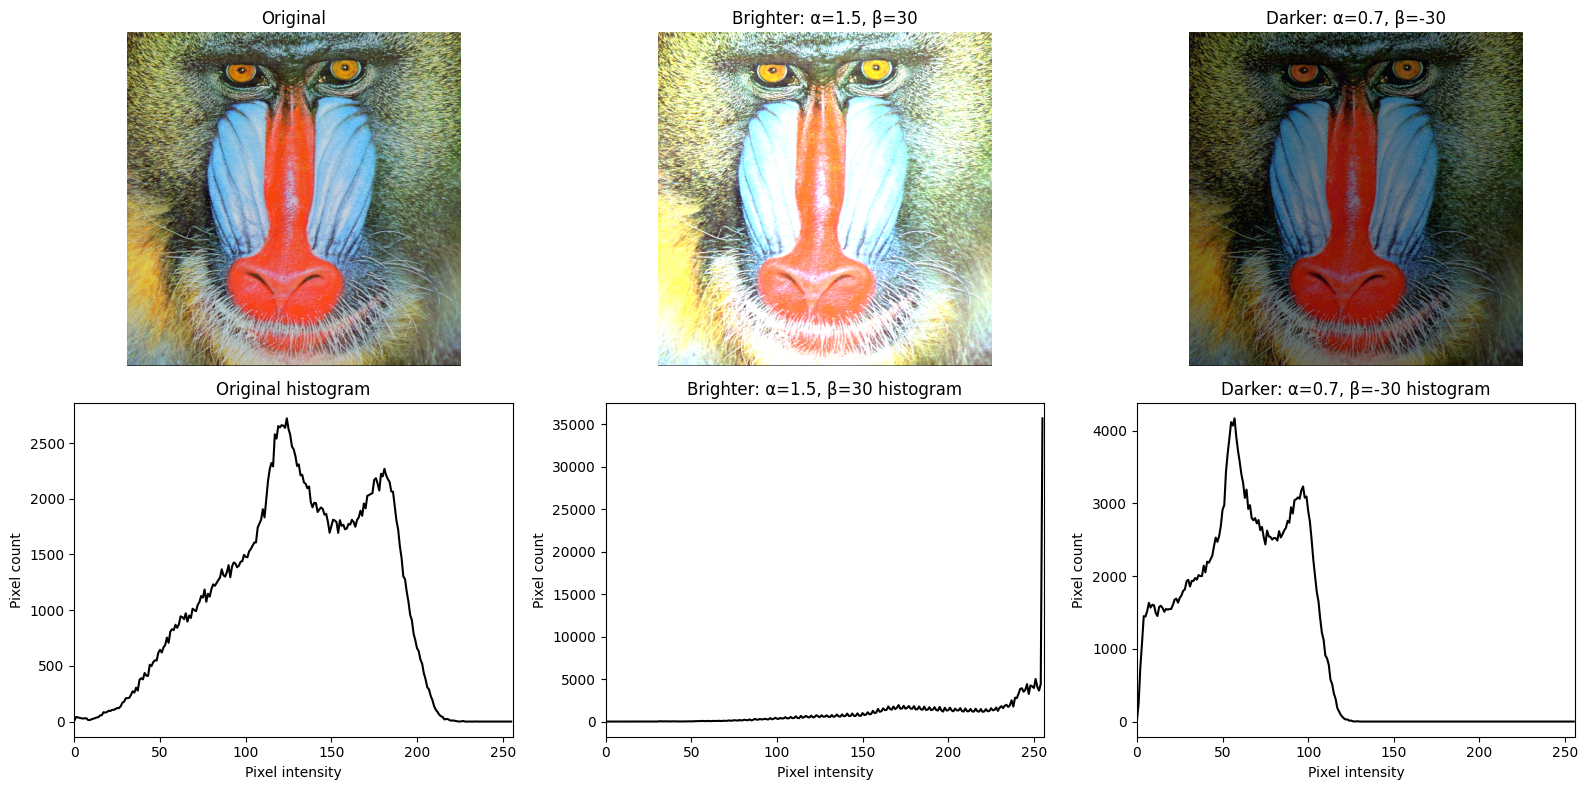

In [ ]:
brightened = cv2.convertScaleAbs(img_colour, alpha=1.5, beta=30)
darkened = cv2.convertScaleAbs(img_colour, alpha=0.7, beta=-30)
versions = [(img_colour, "Original"), (brightened, "Brighter: α=1.5, β=30"),
            (darkened, "Darker: α=0.7, β=-30")]
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for col, (im, title) in enumerate(versions):
    show(im, title, ax[0, col])
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    ax[1, col].plot(hist, color="black")
    ax[1, col].set_title(title + " histogram")
    ax[1, col].set_xlabel("Pixel intensity"); ax[1, col].set_ylabel("Pixel count"); ax[1, col].set_xlim(0, 256)
plt.tight_layout()
plt.savefig(PLOT_DIR / "histogram_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 2.5 WHY Alpha/Beta and Histograms Matter

`new_pixel = alpha × pixel + beta`. Alpha controls contrast by stretching/compressing intensity differences; beta shifts brightness. A narrow histogram often means low contrast. Values piled up at 0 or 255 indicate shadow/highlight clipping. This helps decide whether preprocessing is needed before detection, although excessive changes can remove useful detail.

# Task 3: Face Detection with YuNet (OpenCV)

## 3.1 Load YuNet
**Objective:** Download the YuNet ONNX model and check that `cv2.FaceDetectorYN_create` is available.

In [ ]:
yunet_path = MODEL_DIR / "face_detection_yunet_2023mar.onnx"
yunet_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
download_file(yunet_url, yunet_path)
yunet_available = hasattr(cv2, "FaceDetectorYN_create") and yunet_path.exists()
print("FaceDetectorYN API available:", hasattr(cv2, "FaceDetectorYN_create"))
print("YuNet model exists:", yunet_path.exists())

Downloaded: data/models/face_detection_yunet_2023mar.onnx
FaceDetectorYN API available: True
YuNet model exists: True


## 3.2 Detect Faces on Static Images
**Objective:** Draw face boxes, five landmarks, and confidence scores on sample images. Use your own photos with varied pose/lighting and partial occlusion for the full PDF requirement.

zidane.jpg face count: 3


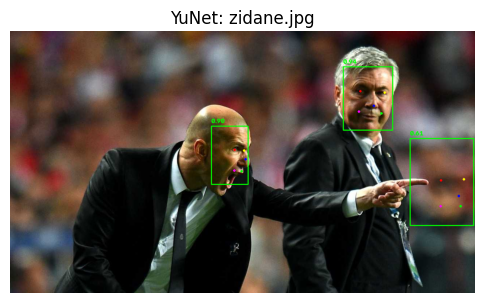

baboon.jpg face count: 0


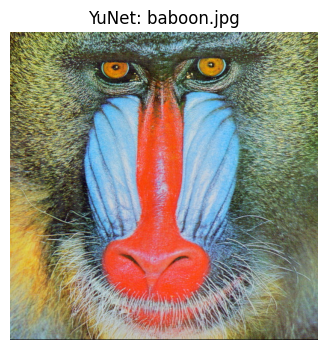

bus.jpg face count: 2


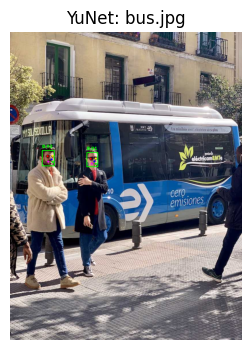

In [ ]:
def create_yunet(image, score_threshold=0.5):
    h, w = image.shape[:2]
    return cv2.FaceDetectorYN_create(str(yunet_path), "", (w, h),
        score_threshold=score_threshold, nms_threshold=0.3, top_k=5000)

def draw_faces(image, faces):
    output = image.copy()
    if faces is None:
        return output
    landmark_colours = [(0,0,255), (0,255,255), (255,0,0), (255,0,255), (0,255,0)]
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        cv2.rectangle(output, (x,y), (x+w,y+h), (0,255,0), 2)
        for i, colour in enumerate(landmark_colours):
            cv2.circle(output, (int(face[4+2*i]), int(face[5+2*i])), 2, colour, 2)
        cv2.putText(output, f"{face[-1]:.2f}", (x, max(20,y-8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)
    return output

if yunet_available:
    for name in ["zidane.jpg", "baboon.jpg", "bus.jpg"]:
        image = cv2.imread(str(IMAGE_DIR / name))
        detector = create_yunet(image, 0.5)
        _, faces = detector.detect(image)
        print(name, "face count:", 0 if faces is None else len(faces))
        show(draw_faces(image, faces), "YuNet: " + name)
        plt.show()
else:
    print("YuNet skipped: model/API unavailable. Check model URL and OpenCV build.")

## 3.3 Real-Time YuNet Webcam Detection
**Objective:** Run YuNet on webcam frames and report average FPS. This function is optional; run `run_yunet_webcam()` locally and press `q` to quit.

In [ ]:
def run_yunet_webcam(camera_index=0, score_threshold=0.7):
    if not yunet_available:
        print("YuNet unavailable."); return
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Could not open webcam."); return
    detector = None
    frames = 0
    start = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            h, w = frame.shape[:2]
            if detector is None:
                detector = cv2.FaceDetectorYN_create(str(yunet_path), "", (w,h),
                    score_threshold=score_threshold, nms_threshold=0.3, top_k=5000)
            else:
                detector.setInputSize((w,h))
            _, faces = detector.detect(frame)
            out = draw_faces(frame, faces)
            frames += 1
            fps = frames / max(time.time()-start, 1e-6)
            cv2.putText(out, f"FPS: {fps:.1f}", (15,30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,255,0), 2)
            cv2.imshow("YuNet webcam — q to quit", out)
            if cv2.waitKey(1) & 0xFF == ord("q"): break
    finally:
        cap.release(); cv2.destroyAllWindows()
    elapsed = time.time()-start
    print("Average YuNet FPS:", frames / elapsed if elapsed else 0)

## 3.4 Score-Threshold Experiment & Privacy Blur
**Objective:** Compare detection counts at thresholds 0.5, 0.7, and 0.9, then blur detected face regions.

Face counts by threshold: {0.5: 3, 0.7: 2, 0.9: 2}


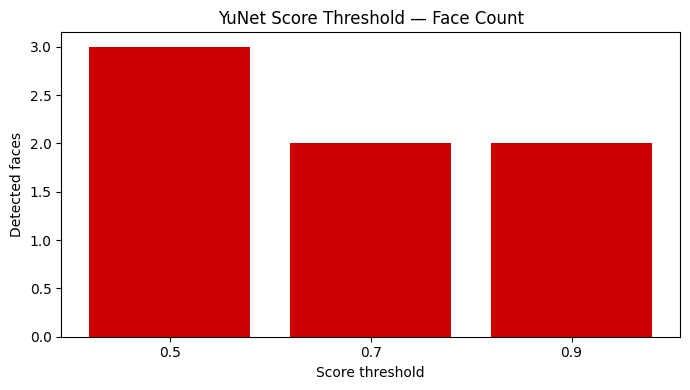

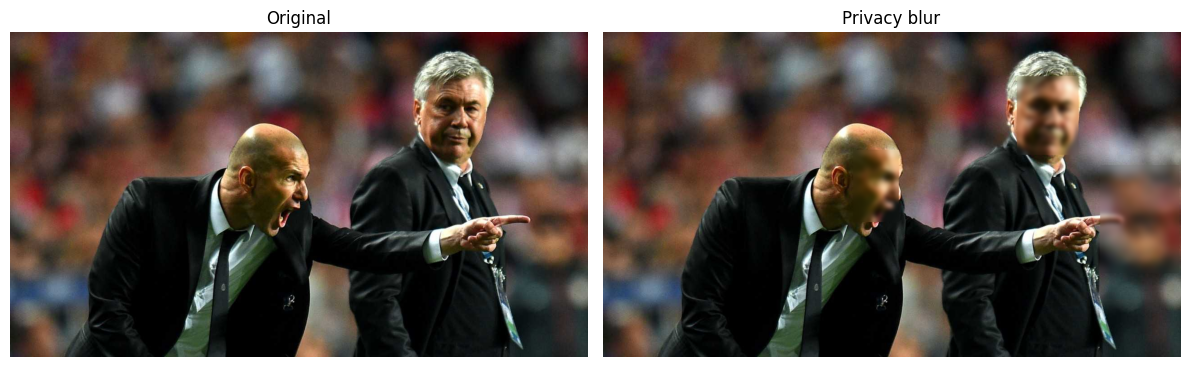

In [ ]:
if yunet_available:
    face_image = cv2.imread(str(IMAGE_DIR / "zidane.jpg"))
    counts = {}
    for threshold in [0.5, 0.7, 0.9]:
        detector = create_yunet(face_image, threshold)
        _, faces = detector.detect(face_image)
        counts[threshold] = 0 if faces is None else len(faces)
    print("Face counts by threshold:", counts)
    plt.figure(figsize=(7,4))
    plt.bar([str(k) for k in counts], list(counts.values()), color="#CC0000")
    plt.title("YuNet Score Threshold — Face Count")
    plt.xlabel("Score threshold"); plt.ylabel("Detected faces"); plt.tight_layout(); plt.show()

    detector = create_yunet(face_image, 0.5)
    _, faces = detector.detect(face_image)
    blurred = face_image.copy()
    if faces is not None:
        for face in faces:
            x,y,w,h = face[:4].astype(int)
            x1,y1 = max(0,x),max(0,y); x2,y2 = min(blurred.shape[1],x+w),min(blurred.shape[0],y+h)
            if x2>x1 and y2>y1:
                blurred[y1:y2,x1:x2] = cv2.GaussianBlur(blurred[y1:y2,x1:x2], (31,31), 0)
    fig, ax = plt.subplots(1,2,figsize=(12,5))
    show(face_image,"Original",ax[0]); show(blurred,"Privacy blur",ax[1])
    plt.tight_layout(); plt.show()
else:
    print("Threshold and blur experiment skipped because YuNet is unavailable.")

## 3.5 WHY YuNet

YuNet is a compact CNN-based face detector exposed through OpenCV's `FaceDetectorYN` API. It returns a bounding box, five facial landmarks, and a confidence score. Lower thresholds generally accept more candidates but can increase false positives; higher thresholds are more conservative but may miss difficult faces. Tune the threshold using representative footage for security cameras or offline photo tagging.

# Task 4: Object Detection with YOLO

## 4.1 Load YOLOv8n and Run on Static Images
**Objective:** Load pretrained YOLOv8 Nano and display rendered detections on static photos. The weights download on first use.

In [ ]:
yolo_available = False
yolo_model = None
try:
    from ultralytics import YOLO
    yolo_model = YOLO("yolov8n.pt")
    yolo_available = True
    print("YOLOv8n loaded.")
except Exception as exc:
    print("YOLOv8 unavailable:", exc)

class_counts = Counter()
if yolo_available:
    for name in ["bus.jpg", "zidane.jpg", "smarties.png"]:
        result = yolo_model(str(IMAGE_DIR / name), verbose=False)[0]
        show(result.plot(), "YOLOv8 detections: " + name)
        plt.show()
        if result.boxes is not None:
            for class_id in result.boxes.cls.cpu().numpy().astype(int):
                class_counts[yolo_model.names[int(class_id)]] += 1

YOLOv8 unavailable: No module named 'ultralytics'


## 4.2 Real-Time YOLO Webcam Detection
**Objective:** Run YOLO on webcam frames and report FPS. Run `run_yolo_webcam()` locally; press `q` to quit.

In [ ]:
def run_yolo_webcam(camera_index=0, conf=0.25, iou=0.5):
    if not yolo_available:
        print("YOLO unavailable."); return
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Could not open webcam."); return
    frames = 0
    start = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            result = yolo_model(frame, conf=conf, iou=iou, verbose=False)[0]
            out = result.plot()
            frames += 1
            cv2.putText(out, f"FPS: {frames/max(time.time()-start,1e-6):.1f}",
                        (15,30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,255,0), 2)
            cv2.imshow("YOLO webcam — q to quit", out)
            if cv2.waitKey(1) & 0xFF == ord("q"): break
    finally:
        cap.release(); cv2.destroyAllWindows()
    elapsed = time.time()-start
    print("Average YOLO FPS:", frames/elapsed if elapsed else 0)

## 4.3 Confidence & IoU Threshold Tuning
**Objective:** Compare retained box counts for confidence thresholds 0.25/0.5/0.75 and IoU thresholds 0.3/0.5/0.7.

In [ ]:
if yolo_available:
    test_path = str(IMAGE_DIR / "bus.jpg")
    conf_counts, iou_counts = {}, {}
    for conf in [0.25, 0.5, 0.75]:
        result = yolo_model(test_path, conf=conf, iou=0.5, verbose=False)[0]
        conf_counts[conf] = 0 if result.boxes is None else len(result.boxes)
    for iou in [0.3, 0.5, 0.7]:
        result = yolo_model(test_path, conf=0.25, iou=iou, verbose=False)[0]
        iou_counts[iou] = 0 if result.boxes is None else len(result.boxes)
    fig, ax = plt.subplots(1,2,figsize=(12,4))
    ax[0].plot(list(conf_counts), list(conf_counts.values()), marker="o")
    ax[0].set_title("Confidence vs retained boxes"); ax[0].set_xlabel("Confidence"); ax[0].set_ylabel("Box count")
    ax[1].plot(list(iou_counts), list(iou_counts.values()), marker="o", color="#CC0000")
    ax[1].set_title("IoU vs retained boxes"); ax[1].set_xlabel("IoU"); ax[1].set_ylabel("Box count")
    plt.tight_layout(); plt.show()

    low_iou = yolo_model(test_path, conf=0.1, iou=0.3, verbose=False)[0]
    high_iou = yolo_model(test_path, conf=0.1, iou=0.7, verbose=False)[0]
    fig, ax = plt.subplots(1,2,figsize=(14,6))
    show(low_iou.plot(), "YOLO IoU=0.3", ax[0]); show(high_iou.plot(), "YOLO IoU=0.7", ax[1])
    plt.tight_layout(); plt.show()
else:
    print("YOLO threshold tuning skipped.")

YOLO threshold tuning skipped.


## 4.4 Per-Class Detection Summary
**Objective:** Plot the number of detections per COCO class across the static images.

In [ ]:
if class_counts:
    names = list(class_counts.keys())
    values = list(class_counts.values())
    order = np.argsort(values)
    plt.figure(figsize=(10, max(4, len(names)*0.35)))
    plt.barh([names[i] for i in order], [values[i] for i in order], color="#CC0000")
    plt.title("YOLOv8 — Per-Class Detection Counts")
    plt.xlabel("Detection count"); plt.ylabel("COCO class"); plt.tight_layout()
    plt.savefig(PLOT_DIR / "yolo_detections.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(dict(class_counts))
else:
    print("No detection counts available.")

No detection counts available.


## 4.5 WHY YOLO Generalises

YOLO is a single-stage detector that predicts boxes and class probabilities in one forward pass, then applies Non-Maximum Suppression (NMS) to reduce duplicate detections. YOLOv8n prioritises speed and low compute, usually trading some accuracy for that speed compared with larger variants. Its pretrained COCO weights recognise 80 classes without per-class hand-tuning, but small objects, occlusion, unusual viewpoints, low light, and unseen classes can reduce performance.

# Task 5: Integrated Pipeline & Final Comparison

## 5.1 Build the Unified Pipeline
**Objective:** Overlay YuNet face detections (green) and YOLO object detections (red/class labels) on a single webcam stream. Run `run_integrated_pipeline()` locally and press `q` to quit.

In [ ]:
def run_integrated_pipeline(camera_index=0, face_threshold=0.7, yolo_conf=0.25,
                            yolo_iou=0.5, morphology_preclean=False):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Could not open webcam."); return
    face_detector = None
    frames = 0
    start = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            detect_frame = frame.copy()
            if morphology_preclean:
                gray = cv2.cvtColor(detect_frame, cv2.COLOR_BGR2GRAY)
                _, mask = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
                mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
                detect_frame = cv2.bitwise_and(detect_frame, detect_frame, mask=mask)

            if yolo_available:
                result = yolo_model(detect_frame, conf=yolo_conf, iou=yolo_iou, verbose=False)[0]
                output = result.plot()
            else:
                output = frame.copy()

            if yunet_available:
                h, w = frame.shape[:2]
                if face_detector is None:
                    face_detector = cv2.FaceDetectorYN_create(str(yunet_path), "", (w,h),
                        score_threshold=face_threshold, nms_threshold=0.3, top_k=5000)
                else:
                    face_detector.setInputSize((w,h))
                _, faces = face_detector.detect(frame)
                if faces is not None:
                    for face in faces:
                        x,y,fw,fh = face[:4].astype(int)
                        cv2.rectangle(output,(x,y),(x+fw,y+fh),(0,255,0),2)
                        cv2.putText(output,f"Face {face[-1]:.2f}",(x,max(20,y-8)),
                                    cv2.FONT_HERSHEY_SIMPLEX,0.55,(0,255,0),2)
            frames += 1
            fps = frames / max(time.time()-start, 1e-6)
            cv2.putText(output,f"FPS: {fps:.1f}",(15,30),cv2.FONT_HERSHEY_SIMPLEX,0.8,(255,255,0),2)
            cv2.imshow("Integrated YuNet + YOLO — q to quit", output)
            if cv2.waitKey(1) & 0xFF == ord("q"): break
    finally:
        cap.release(); cv2.destroyAllWindows()
    elapsed = time.time()-start
    print("Average combined FPS:", frames/elapsed if elapsed else 0)

## 5.2 Morphological Pre-Cleaning
**Objective:** Show a mask before and after opening. Test the live pipeline with and without `morphology_preclean=True` and compare detections.

Note: applying a threshold mask directly to a colour frame can remove useful content. Use this as an experiment and only keep preprocessing if the measured detections improve.

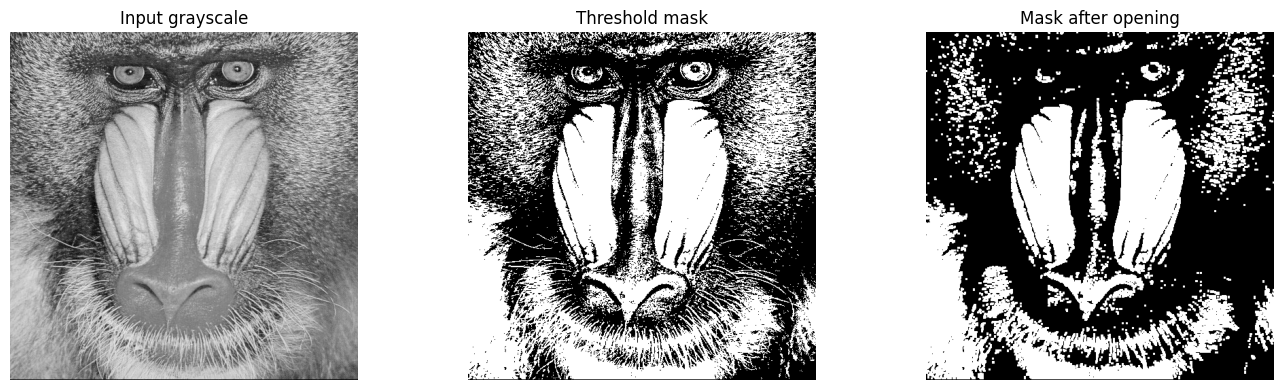

Compare live results by calling run_integrated_pipeline(morphology_preclean=False) and True.


In [ ]:
gray_frame = cv2.cvtColor(img_colour, cv2.COLOR_BGR2GRAY)
_, raw_mask = cv2.threshold(gray_frame, 127, 255, cv2.THRESH_BINARY)
clean_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
fig, ax = plt.subplots(1,3,figsize=(14,4))
show(gray_frame, "Input grayscale", ax[0])
show(raw_mask, "Threshold mask", ax[1])
show(clean_mask, "Mask after opening", ax[2])
plt.tight_layout(); plt.show()
print("Compare live results by calling run_integrated_pipeline(morphology_preclean=False) and True.")

## 5.3 FPS Benchmarking
**Objective:** Measure FPS for YuNet-only, YOLO-only, and combined inference on the same 100 webcam frames. Run `benchmark_pipeline_fps()` locally; measured values will vary by hardware.

In [ ]:
def benchmark_pipeline_fps(camera_index=0, frame_limit=100):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Could not open webcam; benchmark skipped."); return None
    frames = []
    try:
        while len(frames) < frame_limit:
            ok, frame = cap.read()
            if not ok: break
            frames.append(frame)
    finally:
        cap.release()
    if not frames:
        print("No frames captured."); return None

    results = {}
    if yunet_available:
        detector = None
        start = time.perf_counter()
        for frame in frames:
            h,w = frame.shape[:2]
            if detector is None:
                detector = cv2.FaceDetectorYN_create(str(yunet_path), "", (w,h),
                    score_threshold=0.7, nms_threshold=0.3, top_k=5000)
            else:
                detector.setInputSize((w,h))
            detector.detect(frame)
        elapsed = time.perf_counter()-start
        results["YuNet face"] = len(frames)/elapsed if elapsed else 0

    if yolo_available:
        start = time.perf_counter()
        for frame in frames:
            yolo_model(frame, verbose=False)
        elapsed = time.perf_counter()-start
        results["YOLOv8"] = len(frames)/elapsed if elapsed else 0

    if yunet_available or yolo_available:
        detector = None
        start = time.perf_counter()
        for frame in frames:
            if yolo_available:
                yolo_model(frame, verbose=False)
            if yunet_available:
                h,w = frame.shape[:2]
                if detector is None:
                    detector = cv2.FaceDetectorYN_create(str(yunet_path), "", (w,h),
                        score_threshold=0.7, nms_threshold=0.3, top_k=5000)
                else:
                    detector.setInputSize((w,h))
                detector.detect(frame)
        elapsed = time.perf_counter()-start
        results["Combined"] = len(frames)/elapsed if elapsed else 0

    if results:
        print("Measured FPS:", results)
        plt.figure(figsize=(8,4))
        plt.bar(list(results.keys()), list(results.values()), color="#CC0000")
        plt.title(f"FPS Benchmark — {len(frames)} Frames")
        plt.xlabel("Pipeline"); plt.ylabel("Frames per second"); plt.tight_layout()
        plt.savefig(PLOT_DIR / "fps_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
        return results
    print("No detector was available."); return None

## 5.4 Final Results Comparison Table

FPS must be measured on your own hardware. The table below summarises the role of each technique from Tasks 1–4.

In [ ]:
comparison_table = pd.DataFrame([
    ["Morphology", "Classical", "Cleans binary masks", "Low–moderate; depends on threshold", "Measure locally", "Fast mask cleanup"],
    ["Bitwise operations", "Classical", "Combines masks / extracts ROI", "Depends on mask quality", "Measure locally", "ROI extraction and compositing"],
    ["Histograms + alpha/beta", "Classical", "Diagnoses/adjusts intensity", "Preprocessing only", "Measure locally", "Exposure and contrast checks"],
    ["YuNet", "Deep Learning", "Faces, boxes, 5 landmarks, confidence", "Moderate; scene dependent", "Measure locally", "Lightweight face detection/privacy blur"],
    ["YOLOv8n", "Deep Learning", "COCO object classes", "Moderate; scene dependent", "Measure locally", "General object detection"],
], columns=["Technique", "Type", "What It Detects / Does", "Lighting Robustness", "Approx. FPS", "Best Use Case"])
comparison_table

,Technique,Type,What It Detects / Does,Lighting Robustness,Approx. FPS,Best Use Case
0,Morphology,Classical,Cleans binary masks,Low–moderate; depends on threshold,Measure locally,Fast mask cleanup
1,Bitwise operations,Classical,Combines masks / extracts ROI,Depends on mask quality,Measure locally,ROI extraction and compositing
2,Histograms + alpha/beta,Classical,Diagnoses/adjusts intensity,Preprocessing only,Measure locally,Exposure and contrast checks
3,YuNet,Deep Learning,"Faces, boxes, 5 landmarks, confidence",Moderate; scene dependent,Measure locally,Lightweight face detection/privacy blur
4,YOLOv8n,Deep Learning,COCO object classes,Moderate; scene dependent,Measure locally,General object detection


## 5.5 Reflection

For real-time monitoring, combine inexpensive classical preprocessing only when it helps the input mask, YuNet for faces, and YOLOv8n for general objects. For a low-power edge device, use the nano model, reduce frame resolution if acceptable, and tune thresholds using representative footage. On a server with more compute, a larger YOLO variant may improve accuracy at higher cost. Choose YuNet's score threshold based on the cost of missed faces versus false positives.

**Do not invent performance results:** report FPS measured on your own camera and hardware.

## Submission Checklist

- [ ] Save/rename this file to `CV_PR3.ipynb`.
- [ ] Run static cells from top to bottom; resolve package/model downloads if needed.
- [ ] Add 2–3 of your own phone photos, including varied faces and everyday objects, for the full PDF requirement.
- [ ] Run webcam functions locally: `run_yunet_webcam()`, `run_yolo_webcam()`, `run_integrated_pipeline()`.
- [ ] Run `benchmark_pipeline_fps()` and record actual FPS values.
- [ ] Review `plots/`; export the notebook to HTML and upload notebook, HTML, plots and README to GitHub.